#3. Transfer Learning
Using ResNet18 with a 2-phase training schedule.

In [1]:
import sys
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

sys.path.append(str(Path.cwd().parent))

from configs.paths import EUROSAT_DIR, OUTPUTS_DIR
from data.dataset_loader import SatelliteDatasetLoader
from models.resnet_transfer import ResNet18Transfer
from training.trainer import Trainer

# Load Data
loader = SatelliteDatasetLoader(EUROSAT_DIR, split_type='random')
train_loader, val_loader, test_loader = loader.get_dataloaders()
classes = loader.classes
num_classes = len(classes)

2026-07-12 19:24:29,120 - INFO - DatasetLoader - Loaded dataset from D:\Main Project\data\datasets\eurosat\EuroSAT containing 27000 images across 10 classes.
2026-07-12 19:24:29,121 - INFO - DatasetLoader - Generating Random split indices...
2026-07-12 19:24:29,308 - INFO - DatasetLoader - Successfully generated DataLoaders. Train size: 18900, Val size: 4050, Test size: 4050


## Phase 1: Freeze Backbone & Train Classifier Head

In [2]:
model = ResNet18Transfer(num_classes=num_classes)
model.freeze_backbone() # Freeze resnet parameters except the last layer

criterion = torch.nn.CrossEntropyLoss()
optimizer1 = torch.optim.Adam(model.parameters(), lr=0.001)

trainer = Trainer(model, criterion, optimizer1)
save_path = str(OUTPUTS_DIR / 'resnet18_best.pth')

print("Training Phase 1: Classifier only for 3 epochs")
history_phase1 = trainer.train(train_loader, val_loader, epochs=3, save_path=save_path)

2026-07-12 19:24:29,460 - INFO - Trainer - Starting model training for 3 epochs...


Training Phase 1: Classifier only for 3 epochs


Training Batch:   0%|          | 0/591 [00:00<?, ?it/s]d:\Main Project\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
2026-07-12 19:31:03,732 - INFO - Evaluator - Evaluation Complete. Accuracy: 0.8691 | Macro F1: 0.8660
2026-07-12 19:31:03,735 - INFO - Trainer - Epoch 1/3 Summary: Train Loss: 0.7575 | Train Acc: 0.7753 || Val Loss: 0.4334 | Val Acc: 0.8691 | Val F1: 0.8660
2026-07-12 19:31:03,776 - INFO - Trainer - -> Saved new best checkpoint to: D:\Main Project\outputs\resnet18_best.pth (Acc: 0.8691)
Training Batch:   0%|          | 0/591 [00:00<?, ?it/s]d:\Main Project\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
2026-07-12 19:37:23,897 - INFO - Evaluator - Evaluat

## Phase 2: Unfreeze Last Two Residual Blocks & Fine-tune

In [3]:
model.unfreeze_last_two_blocks()

# Reduce LR by 10x for fine-tuning
optimizer2 = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.0001)
trainer.optimizer = optimizer2

print("\nTraining Phase 2: Fine-tuning for 5 epochs")
history_phase2 = trainer.train(train_loader, val_loader, epochs=5, save_path=save_path)

2026-07-12 19:43:50,225 - INFO - Trainer - Starting model training for 5 epochs...



Training Phase 2: Fine-tuning for 5 epochs


Training Batch:   0%|          | 0/591 [00:00<?, ?it/s]d:\Main Project\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
2026-07-12 19:54:21,353 - INFO - Evaluator - Evaluation Complete. Accuracy: 0.9568 | Macro F1: 0.9558
2026-07-12 19:54:21,356 - INFO - Trainer - Epoch 1/5 Summary: Train Loss: 0.2492 | Train Acc: 0.9193 || Val Loss: 0.1415 | Val Acc: 0.9568 | Val F1: 0.9558
2026-07-12 19:54:21,399 - INFO - Trainer - -> Saved new best checkpoint to: D:\Main Project\outputs\resnet18_best.pth (Acc: 0.9568)
Training Batch:   0%|          | 0/591 [00:00<?, ?it/s]d:\Main Project\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
2026-07-12 20:05:16,040 - INFO - Evaluator - Evaluat

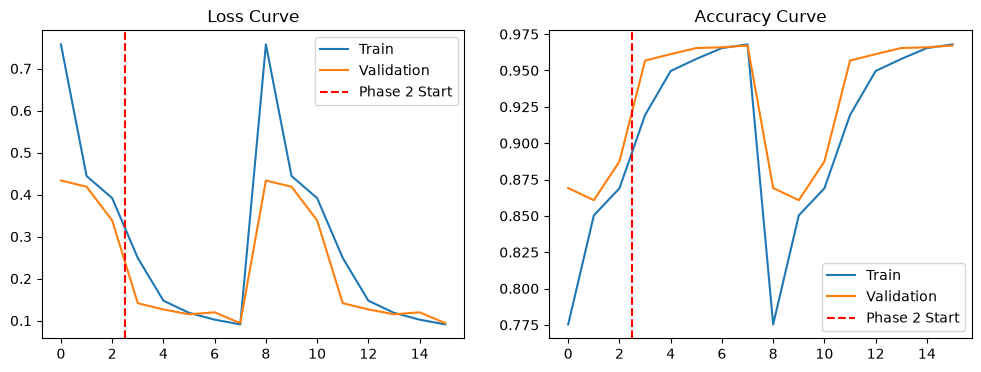

In [4]:
# Merge Histories
history_combined = {k: history_phase1[k] + history_phase2[k] for k in history_phase1.keys()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_combined['train_loss'], label='Train')
ax1.plot(history_combined['val_loss'], label='Validation')
ax1.axvline(x=2.5, color='r', linestyle='--', label='Phase 2 Start')
ax1.set_title('Loss Curve')
ax1.legend()

ax2.plot(history_combined['train_acc'], label='Train')
ax2.plot(history_combined['val_acc'], label='Validation')
ax2.axvline(x=2.5, color='r', linestyle='--', label='Phase 2 Start')
ax2.set_title('Accuracy Curve')
ax2.legend()
plt.show()

In [6]:
# Final Evaluation
loss, acc, prec, rec, macro_f1, y_true, y_pred = trainer.evaluate(val_loader)

print(f"Validation Metrics:\nAccuracy: {acc:.4f}\nPrecision: {prec:.4f}\nRecall: {rec:.4f}\nMacro F1: {macro_f1:.4f}")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_true, y_pred, target_names=classes))

AttributeError: 'Trainer' object has no attribute 'evaluate'